In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load Dataset
df = pd.read_csv("Titanic-Dataset.csv")
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [6]:
df.shape

(891, 12)

In [7]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [8]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

# 2. Summary Statistics

In [3]:
df.describe(include='all')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


# 3. Handling Missing Values

In [9]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Cabin'] = df['Cabin'].fillna('Unknown')
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [10]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

## Key Responsibilities & Implementation

## 1. Distribution Analysis

Text(0.5, 1.0, 'Fare by Class in $')

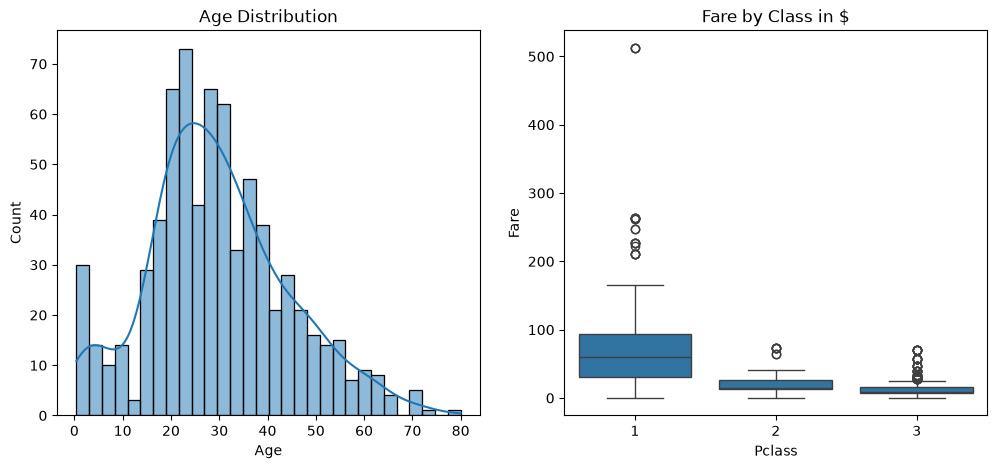

In [ ]:
## 1. Age Distribution & Fare by Class
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df['Age'], bins=30, kde=True, ax=ax[0]).set_title('Age Distribution')
sns.boxplot(x='Pclass', y='Fare', data=df, ax=ax[1]).set_title('Fare by Class in $')

Conclusion:- The age distribution shows that most passengers were young adults, with the highest number around 20 to 30 years old. There were fewer children and very few passengers above 60, and a small group of infants and young children (under 5) forms a separate bump on the left. The distribution is slightly skewed to the right, because older ages are spread out more than younger ones.

The fare boxplot shows a clear difference between classes. Class 1 passengers paid the highest fares, with a median of about 60 and a wide spread, and some paid more than 200, up to about 500. Class 2 and Class 3 fares are much lower and close together, with most fares below 30. All three classes have outliers, but Class 1 has the most extreme ones. This shows that ticket price is strongly linked to passenger class.

2. Survival by Gender

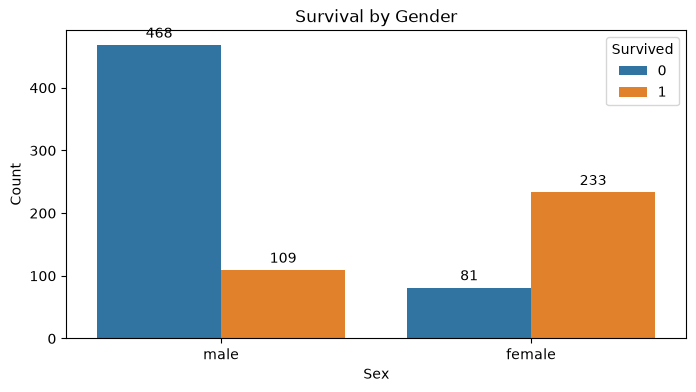

In [ ]:
plt.figure(figsize=(8, 4))

ax = sns.countplot(x='Sex', hue='Survived', data=df)

# Add count labels on each column
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.title('Survival by Gender')
plt.xlabel('Sex')
plt.ylabel('Count')

plt.show()

Conclusion:- Gender played a major role in survival outcomes: the vast majority of male passengers did not survive (468 vs. 109 survivors), whereas female passengers had a substantially higher survival rate (233 survived vs. 81 did not). This strong disparity reflects the "women and children first" evacuation protocol.

## 2. Correlation & Relationships

<Axes: >

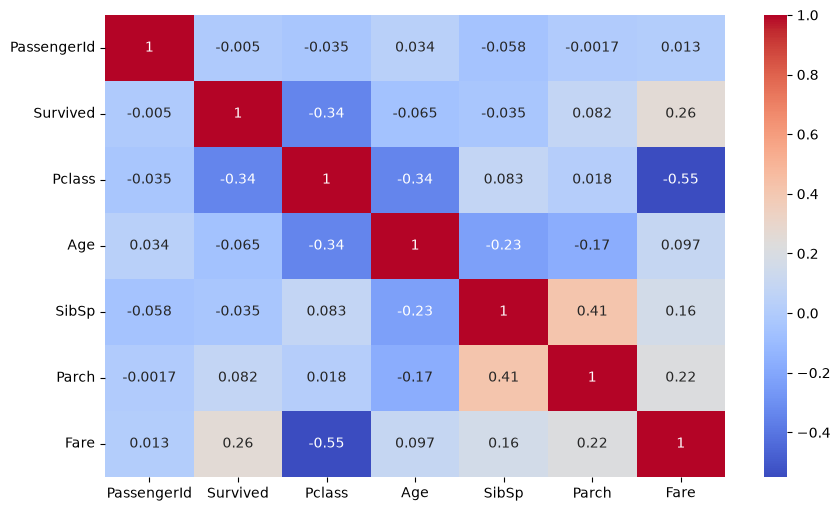

In [ ]:
# Correlation Matrix (Heatmap)
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')

Conclusion:- Rich passengers (higher class, higher fare) survived more. Age and family size did not matter much.

In [ ]:
# Cross-Tabulation (Categorical Relationships)
pd.crosstab(df['Pclass'], df['Survived'], normalize='index') * 100

Survived,0,1
Pclass,,
1,37.037037,62.962963
2,52.717391,47.282609
3,75.763747,24.236253


## 3. Outlier Detection

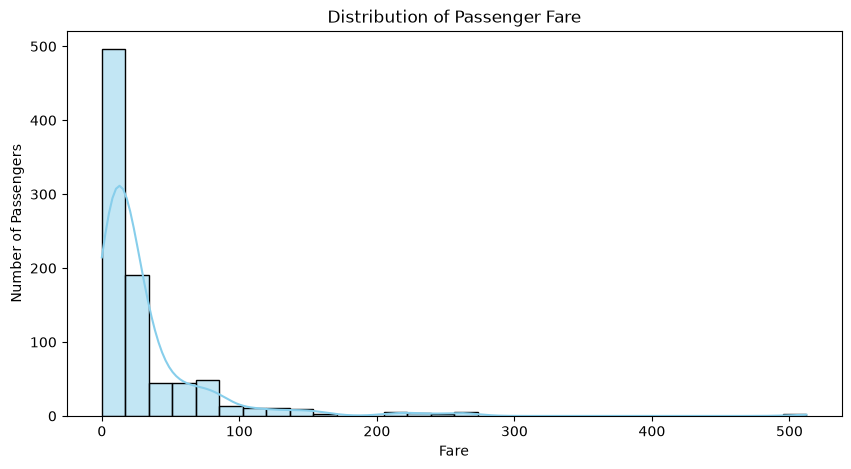

In [ ]:
# Distribution of Passenger Fare
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='Fare', bins=30, kde=True, color='skyblue')

plt.title('Distribution of Passenger Fare')
plt.xlabel('Fare')
plt.ylabel('Number of Passengers')

plt.show()

Conclusion:- The distribution of passenger fares is heavily right-skewed, with the vast majority of passengers paying low fares under $50 (and nearly 500 concentrated in the lowest bin). Passenger counts drop sharply as fares increase, leaving a long tail of a few high-fare outliers extending past $200 and up to around $512.

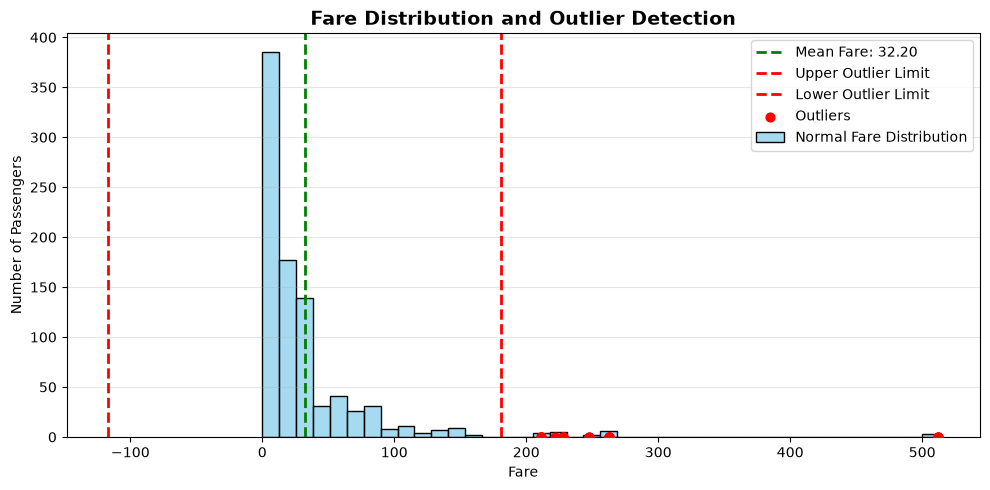

Total Fare Outliers: 20
Mean Fare: 32.20
Standard Deviation: 49.67


In [ ]:
# Fare Distribution and Outlier Detection
fare = df['Fare'].dropna()

mean = np.mean(fare)
std = np.std(fare)

z_scores = np.abs((fare - mean) / std)

# Identify outliers
outliers = fare[z_scores > 3]

# Create a better visualization
plt.figure(figsize=(10, 5))

sns.histplot(fare, bins=40, color='skyblue', edgecolor='black',
             label='Normal Fare Distribution')

plt.axvline(mean, color='green', linestyle='--',
            linewidth=2, label=f'Mean Fare: {mean:.2f}')

plt.axvline(mean + 3 * std, color='red', linestyle='--',
            linewidth=2, label='Upper Outlier Limit')

plt.axvline(mean - 3 * std, color='red', linestyle='--',
            linewidth=2, label='Lower Outlier Limit')

plt.scatter(outliers, np.zeros(len(outliers)),
            color='red', s=40, label='Outliers', zorder=5)

plt.title('Fare Distribution and Outlier Detection',
          fontsize=14, fontweight='bold')

plt.xlabel('Fare')
plt.ylabel('Number of Passengers')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Total Fare Outliers: {len(outliers)}")
print(f"Mean Fare: {mean:.2f}")
print(f"Standard Deviation: {std:.2f}")

Conclusion:- Most passengers paid low fares, and the average fare is about $32.20. Fares above roughly $180 are outliers, and there are only a few of them, with the highest near $500. These outliers pull the average up, so the fare data is right-skewed.

## 4. Advanced Visualizations

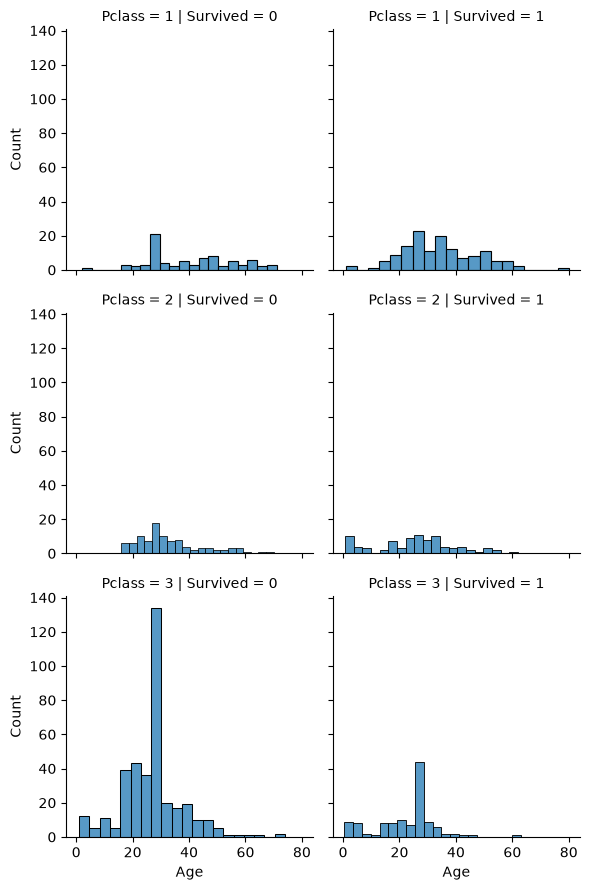

In [ ]:
# Faceted Analysis
g = sns.FacetGrid(df, col='Survived', row='Pclass', height=3)
g.map(sns.histplot, 'Age', bins=20)

Conclusion:- Survival depends mostly on passenger class, not age. In Class 1, more passengers survived than died. In Class 3, far more passengers died than survived, mostly young adults aged 20 to 35. Class 2 is more balanced. Children (under about 10) have a better chance of surviving in Class 2 and 3.

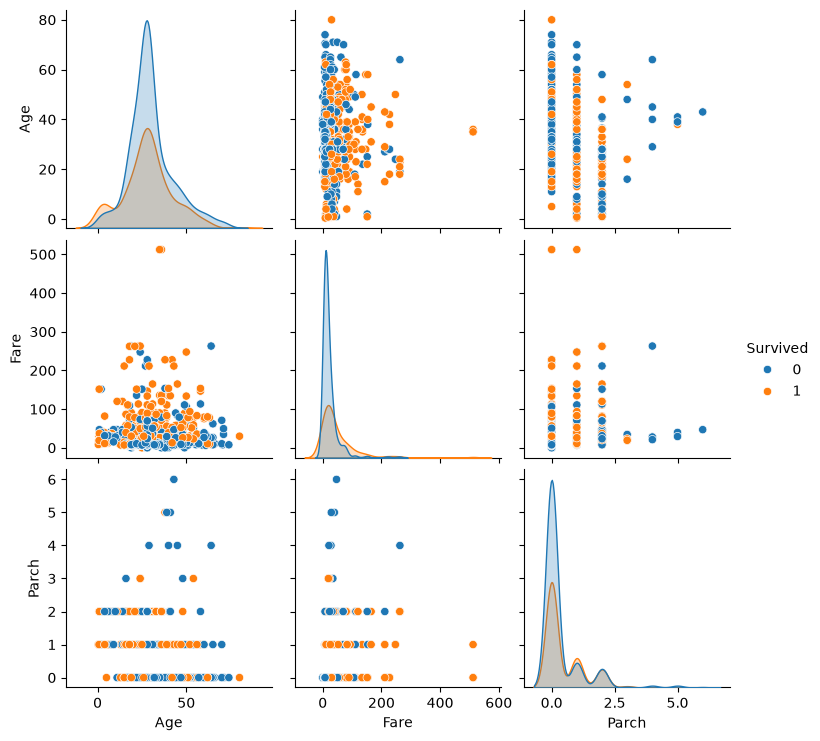

In [18]:
# Pairplot for Multivariate Analysis
sns.pairplot(df[['Age', 'Fare', 'Parch', 'Survived']], hue='Survived')

Conclusion:- Passengers who paid higher fares (above about 100) mostly survived, while those who paid low fares mostly died. Most passengers were aged 20 to 40 and travelled with no parents or children. Young children had a slightly better chance of surviving, and passengers with 3 or more parents/children aboard (Parch) mostly did not survive. Age and Parch overlap heavily between survivors and non-survivors, so they are weak predictors on their own.

Overall Conclusion:- 
This analysis of the Titanic dataset (891 passengers) shows that survival was strongly linked to gender and passenger class, while age and family size had only a small effect. Overall, about 38.4% of passengers survived.

1. Data preparation: Missing Age values (177) were filled with the median, missing Embarked values (2) with the most common value, and missing Cabin values (687) were marked as "Unknown". No missing values remain.

2. Gender: Gender was the strongest factor. Only 109 of 577 male passengers survived (468 did not), while 233 of 314 female passengers survived (81 did not). This reflects the "women and children first" evacuation rule.

3. Passenger class: Survival fell sharply with class: 63.0% of Class 1 passengers survived, compared with 47.3% in Class 2 and only 24.2% in Class 3. Class has a moderate negative correlation with survival (-0.34), and fare has a weak positive correlation (0.26).

4. Fare and outliers: Most passengers paid low fares, and the average fare is 32.20. Class 1 fares are much higher than Class 2 and Class 3 fares, which are low and close together. The z-score method found 20 fare outliers (fares above roughly 180, up to about 512), which make the fare data right-skewed.

5. Age and family size: Most passengers were young adults aged 20 to 35. Age (-0.065), SibSp (-0.035) and Parch (0.082) had very weak correlation with survival, although young children had a slightly better chance of surviving, especially in Class 2 and Class 3.

Overall, being female and travelling in a higher class gave the best chance of survival, while male passengers and Class 3 passengers had the lowest. Correlation shows a relationship, not a cause, and the median-filled ages create an artificial peak at about 28 years, so age results should be read with care.